# 03 — ARIMA / SARIMA (Python)

**Project:** *Did Bitcoin miners leave Bitcoin for AI?* — Phase 3. Equivalent R version: `notebooks/r/03_arima.Rmd`.

| | |
|---|---|
| **Input** | `data/processed/panel.parquet`, split and pivot from `config.yaml`, Phase 2 conclusions |
| **Outputs** | `results/forecasts_arima.csv` (common format), `results/03_*.csv`, `figures/fig_03_*.png` |
| **Brief** | §3.1 (ACF/PACF identification + automatic search, full residual diagnostics), §6 (forecasts h = 5 and 10 with intervals) |

**Target series:** log level of the **CONVERTS** index (d = 1 established in Phase 2). The same pipeline is applied to **PURE** for comparison.
All models are estimated on the **training sample only** (1,102 days); the test sample is used only to evaluate forecasts.

In [1]:
# Resolve the project root from wherever Jupyter was launched, so only relative paths are needed.
import sys, warnings
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pmdarima as pm
from scipy import stats
from statsmodels.graphics.tsaplots import plot_acf
from src import config, data, arima, plotting

SEED = config.set_seed()   # ML estimation is deterministic, the seed only matters for consistency across notebooks
cfg = config.load_config()
plotting.set_style()
pd.set_option("display.width", 170, "display.max_columns", 30, "display.precision", 4)
RES = config.path("results")
print("root:", ROOT.name, "| seed:", SEED, "| pmdarima", pm.__version__)

root: Bitcoin miners | seed: 42 | pmdarima 2.1.1


In [2]:
# Same frozen snapshot and same chronological split as every other notebook (dates checked against config.yaml).
panel = data.load_panel()
train, test = data.chrono_split(panel)
assert str(train.index[-1].date()) == cfg["split"]["train_end"]
SERIES = ["CONVERTS", "PURE"]
logy = {s: panel[f"{s}_log_price"] for s in SERIES}
y_tr = {s: train[f"{s}_log_price"] for s in SERIES}
print(f"train {len(train)} obs ({train.index[0].date()} -> {train.index[-1].date()}) | test {len(test)} obs | pivot {cfg['pivot_date']}")

train 1102 obs (2021-12-14 -> 2026-05-06) | test 123 obs | pivot 2025-01-22


## 1. Manual identification from the ACF / PACF (Phase 2)

**What Phase 2 established:**
* the log price is I(1): ADF does not reject the unit root, KPSS rejects stationarity, the ACF decays slowly. So **d = 1**;
* on returns (the differenced series), the ACF and PACF show **no significant spike** at the first lags. The few isolated exceedances (lags 24 and 26 for CONVERTS) form no pattern;
* Ljung-Box on returns does not reject the absence of autocorrelation (CONVERTS: p = 0.37 / 0.24 / 0.57 at lags 5 / 10 / 20).

**Manual proposal: ARIMA(0,1,0) without drift**, i.e. a random walk on the log price: ln P_t = ln P_{t−1} + ε_t.
* No AR term: the PACF has no spike.
* No MA term: the ACF has no spike.
* No drift: the mean daily return (≈ 0.0001) is negligible relative to its std (≈ 0.063).

Competitors to check: ARIMA(0,1,1) and ARIMA(1,1,0), which would add a small dependence at lag 1 (ACF at lag 1 ≈ 0.04, below the band). The chart below redraws the ACF **on the training sample only**, so that identification never looks at the test set.

figures\fig_03_01_acf_train_returns.png


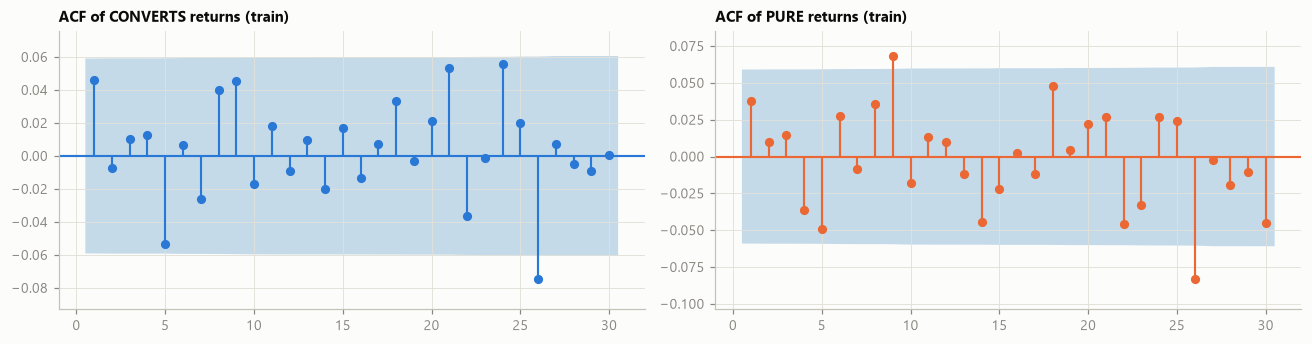

In [3]:
# Re-draw the ACF of TRAIN returns only (phase 2 used the full sample): identification must not look at the test set.
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
for ax, s in zip(axes, SERIES):
    plot_acf(y_tr[s].diff().dropna(), lags=30, zero=False, ax=ax, auto_ylims=True, color=plotting.CORE[s],
             vlines_kwargs={"colors": plotting.CORE[s]}, title=f"ACF of {s} returns (train)")
fig.tight_layout(); print(plotting.save(fig, "fig_03_01_acf_train_returns")); plt.show()

## 2. Automatic search and comparison

Two complementary searches:
* a **full grid** p, q ∈ {0,…,3}, with and without drift (32 models), which shows whether the criterion really separates the models;
* **`pmdarima.auto_arima`** (equivalent of `forecast::auto.arima`), stepwise search, once with d = 1 imposed by Phase 2, once letting the algorithm choose d.

In [4]:
# Full grid on the train log level: shows how flat AIC/BIC are around the best model.
grids = {s: arima.order_grid(y_tr[s]) for s in SERIES}
for s, g in grids.items():
    g.to_csv(RES / f"03_order_grid_{s.lower()}.csv", index=False)
    print(f"--- {s}: 5 best by AIC, then 5 best by BIC")
    print(g.sort_values("AIC").head(5)[["order", "drift", "k", "loglik", "AIC", "dAIC", "BIC", "dBIC"]].to_string(index=False))
    print(g.sort_values("BIC").head(5)[["order", "drift", "k", "loglik", "AIC", "dAIC", "BIC", "dBIC"]].to_string(index=False))

--- CONVERTS: 5 best by AIC, then 5 best by BIC
  order  drift  k    loglik        AIC   dAIC        BIC    dBIC
(0,1,1)  False  2 1479.9825 -2955.9651 0.0000 -2945.9571  4.6301
(1,1,0)  False  2 1479.9615 -2955.9229 0.0422 -2945.9150  4.6723
(0,1,0)  False  1 1478.7956 -2955.5912 0.3739 -2950.5872  0.0000
(0,1,1)   True  3 1480.1100 -2954.2200 1.7451 -2939.2081 11.3791
(1,1,0)   True  3 1480.0887 -2954.1773 1.7878 -2939.1654 11.4218
  order  drift  k    loglik        AIC   dAIC        BIC    dBIC
(0,1,0)  False  1 1478.7956 -2955.5912 0.3739 -2950.5872  0.0000
(0,1,1)  False  2 1479.9825 -2955.9651 0.0000 -2945.9571  4.6301
(1,1,0)  False  2 1479.9615 -2955.9229 0.0422 -2945.9150  4.6723
(0,1,0)   True  2 1478.9339 -2953.8678 2.0973 -2943.8598  6.7274
(0,1,1)   True  3 1480.1100 -2954.2200 1.7451 -2939.2081 11.3791
--- PURE: 5 best by AIC, then 5 best by BIC
  order  drift  k    loglik        AIC   dAIC        BIC    dBIC
(0,1,0)  False  1 1554.1013 -3106.2026 0.0000 -3101.1986  0.000

In [5]:
# auto_arima with d fixed to 1 (phase 2 evidence) and with d chosen by its own unit-root test, to compare both routes.
auto_rows = []
for s in SERIES:
    for label, kw in [("d = 1 imposed", {"d": 1}), ("d chosen by auto_arima", {})]:
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            m = pm.auto_arima(y_tr[s].to_numpy(), seasonal=False, stepwise=True, information_criterion="aic",
                              suppress_warnings=True, error_action="ignore", **kw)
        auto_rows.append({"series": s, "setting": label, "order": m.order, "constant/drift": m.with_intercept,
                          "AIC": m.aic(), "BIC": m.bic()})
auto_tab = pd.DataFrame(auto_rows)
auto_tab.to_csv(RES / "03_auto_arima.csv", index=False)
auto_tab

,series,setting,order,constant/drift,AIC,BIC
0,CONVERTS,d = 1 imposed,"(0, 1, 0)",False,-2955.5912,-2950.5872
1,CONVERTS,d chosen by auto_arima,"(5, 2, 1)",True,-2908.5785,-2868.5540
2,PURE,d = 1 imposed,"(0, 1, 0)",False,-3106.2026,-3101.1986
3,PURE,d chosen by auto_arima,"(0, 1, 0)",False,-3106.2026,-3101.1986


In [6]:
# Why did the free search choose another d? Show the unit-root tests pmdarima uses internally (KPSS by default, then ADF, PP).
nd = pd.DataFrame({s: {t: pm.arima.ndiffs(y_tr[s].to_numpy(), test=t, max_d=2) for t in ("kpss", "adf", "pp")} for s in SERIES})
nd.index.name = "ndiffs test"
nd

,CONVERTS,PURE
ndiffs test,,
kpss,2,1
adf,1,1
pp,1,1


**Manual vs automatic comparison and choice.**

* **Full grid, CONVERTS.** AIC barely separates the models:
  * (0,1,1) comes first, but (1,1,0) is only ΔAIC = 0.04 behind and (0,1,0) ΔAIC = 0.37;
  * an AIC difference below 2 is generally considered not to separate two models.

  **BIC**, which penalises parameters more, chooses **(0,1,0)** with a clear lead (ΔBIC = 4.63 over (0,1,1)). Adding a drift always worsens both criteria (ΔAIC = 2.10 for (0,1,0) with drift).
* **Full grid, PURE.** (0,1,0) without drift is first by both AIC and BIC.
* **`auto_arima` with d = 1** finds exactly the manual choice: **(0,1,0) without constant**, for both series.
* **`auto_arima` with free d** gives a **(5,2,1) with constant** for CONVERTS. The `ndiffs` table explains why: pmdarima's internal KPSS test asks for d = 2 for CONVERTS, while ADF and Phillips-Perron ask for d = 1. With its own settings, KPSS narrowly rejects the stationarity of returns, probably because of changes in volatility. But Phase 2 showed that returns are stationary (ADF p < 0.001, KPSS p ≥ 0.10). Differencing twice would be **over-differencing**: it artificially creates negative autocorrelation and forces useless MA terms. Its AIC is not comparable anyway (it is computed on another series, differenced twice). This model is rejected.
* **The MA coefficient of ARIMA(0,1,1)** is 0.047 (standard error 0.030, see the coefficient table below), i.e. z ≈ 1.6: not significant at 5%.

**Choice: ARIMA(0,1,0) without drift for CONVERTS and PURE.** The manual choice, BIC and `auto_arima` (d = 1) agree, it is the most parsimonious model, and the only parameter added by AIC is not significant. ARIMA(0,1,1) is kept as a competitor for the forecasts, to check in practice that this parameter adds nothing.

Important consequence: the chosen model **is** the random walk. Its point forecast equals the last observed value, so it coincides with the naive baseline required by the brief.

## 3. Seasonality: is a SARIMA term (s = 5) justified?

Three checks:
* **seasonal differencing**: OCSB and Canova-Hansen tests (`pmdarima.nsdiffs`);
* **seasonal AR / MA terms** added to the chosen model, compared by AIC, BIC and likelihood-ratio (LR) test — H0: seasonal coefficients are zero;
* a reminder of the Phase 2 evidence (STL, day-of-week effect).

In [7]:
# Seasonal differencing tests, then nested LR tests of seasonal AR/MA terms on top of the chosen order.
CHOSEN = (0, 1, 0)
seas = []
for s in SERIES:
    base = arima.fit_arima(y_tr[s], CHOSEN)
    seas.append({"series": s, "model": "ARIMA(0,1,0)", "AIC": base.aic, "BIC": base.bic, "LR": np.nan, "df": 0, "p_value": np.nan,
                 "seasonal coefs": "", "D (OCSB)": pm.arima.nsdiffs(y_tr[s].to_numpy(), m=5, test="ocsb"),
                 "D (CH)": pm.arima.nsdiffs(y_tr[s].to_numpy(), m=5, test="ch")})
    for so in [(1, 0, 0, 5), (0, 0, 1, 5), (1, 0, 1, 5)]:
        r = arima.fit_arima(y_tr[s], CHOSEN, seasonal_order=so)
        lr, df = 2 * (r.llf - base.llf), sum(so[:3])
        seas.append({"series": s, "model": f"SARIMA(0,1,0)({so[0]},{so[1]},{so[2]})[5]", "AIC": r.aic, "BIC": r.bic,
                     "LR": lr, "df": df, "p_value": stats.chi2.sf(lr, df),
                     "seasonal coefs": np.round(r.params[:-1], 4).tolist()})
seas = pd.DataFrame(seas)
seas.to_csv(RES / "03_seasonal_tests.csv", index=False)
seas

,series,model,AIC,BIC,LR,df,p_value,seasonal coefs,D (OCSB),D (CH)
0,CONVERTS,"ARIMA(0,1,0)",-2955.5912,-2950.5872,NaN,0,NaN,,0.0,0.0
1,CONVERTS,"SARIMA(0,1,0)(1,0,0)[5]",-2956.7504,-2946.7425,3.1592,1,0.0755,[-0.0538],NaN,NaN
2,CONVERTS,"SARIMA(0,1,0)(0,0,1)[5]",-2956.8628,-2946.8548,3.2716,1,0.0705,[-0.0555],NaN,NaN
3,CONVERTS,"SARIMA(0,1,0)(1,0,1)[5]",-2954.9193,-2939.9073,3.3280,2,0.1894,"[0.222, -0.2754]",NaN,NaN
4,PURE,"ARIMA(0,1,0)",-3106.2026,-3101.1986,NaN,0,NaN,,0.0,0.0
5,PURE,"SARIMA(0,1,0)(1,0,0)[5]",-3106.8822,-3096.8743,2.6796,1,0.1016,[-0.0495],NaN,NaN
6,PURE,"SARIMA(0,1,0)(0,0,1)[5]",-3106.9963,-3096.9883,2.7937,1,0.0946,[-0.0516],NaN,NaN
7,PURE,"SARIMA(0,1,0)(1,0,1)[5]",-3104.5616,-3089.5497,2.3591,2,0.3074,"[-0.1979, 0.1515]",NaN,NaN


**Conclusion: no SARIMA.**
* **Seasonal differencing**: OCSB and Canova-Hansen give **D = 0** for both series.
* **Seasonal terms** (H0: seasonal coefficients are zero): none is significant at 5%. For CONVERTS, LR = 3.16 (p = 0.076) for a seasonal AR, 3.27 (p = 0.070) for a seasonal MA, 3.33 (p = 0.19) for both; for PURE, p = 0.10 / 0.095 / 0.31.
* **Information criteria**: a seasonal term lowers AIC by barely ≈ 1.2 points but **raises BIC** by about 3.8 points (−2,946.7 vs −2,950.6 for CONVERTS). The estimated coefficients (≈ −0.05) are tiny.
* **Consistency with Phase 2**: STL seasonal strength ≤ 0.03 for s = 5, and no day-of-week effect (ANOVA p = 0.61 for CONVERTS).

A seasonal term would therefore complicate the model for a non-significant gain.

## 4. Full residual diagnostics of the chosen model

Tests (5% level):
* **Ljung-Box** — H0: no autocorrelation of the residuals up to lag m (m = 5, 10, 20);
* **Ljung-Box on e² and |e|** — H0: no dependence in the size of the residuals (|e| is less sensitive to isolated jumps than e²);
* **Jarque-Bera** — H0: normal residuals (skewness 0, kurtosis 3); **Shapiro-Wilk** — H0: normal residuals;
* **ARCH-LM** (Engle) — H0: no ARCH effect, the conditional variance is constant (m = 5, 10).

The first residual of a model with d = 1 corresponds to the first observation (diffuse initialisation): it is dropped.

In [8]:
# Fit the chosen model and an AIC-close competitor, then run every diagnostic on both series.
MODELS = {"ARIMA(0,1,0)": ((0, 1, 0), "n"), "ARIMA(0,1,1)": ((0, 1, 1), "n")}
fits, diag = {}, []
for s in SERIES:
    for name, (order, trend) in MODELS.items():
        r = arima.fit_arima(y_tr[s], order, trend)
        fits[(s, name)] = r
        t = arima.residual_diagnostics(r.resid[1:], model_df=order[0] + order[2])
        diag.append(t.assign(series=s, model=name))
diag = pd.concat(diag, ignore_index=True)[["series", "model", "test", "parameter", "H0", "statistic", "p_value", "conclusion (5%)"]]
diag.to_csv(RES / "03_residual_diagnostics.csv", index=False)
diag[diag["model"] == "ARIMA(0,1,0)"].drop(columns="H0")

,series,model,test,parameter,statistic,p_value,conclusion (5%)
0,CONVERTS,"ARIMA(0,1,0)",Ljung-Box,lag 5,5.8644,3.1963e-01,H0 not rejected
1,CONVERTS,"ARIMA(0,1,0)",Ljung-Box,lag 10,11.1134,3.4875e-01,H0 not rejected
2,CONVERTS,"ARIMA(0,1,0)",Ljung-Box,lag 20,14.4548,8.0671e-01,H0 not rejected
3,CONVERTS,"ARIMA(0,1,0)",Ljung-Box on e²,lag 10,4.5957,9.1650e-01,H0 not rejected
4,CONVERTS,"ARIMA(0,1,0)",Ljung-Box on |e|,lag 10,13.0412,2.2138e-01,H0 not rejected
5,CONVERTS,"ARIMA(0,1,0)",Jarque-Bera,,43.8352,3.0290e-10,reject H0
6,CONVERTS,"ARIMA(0,1,0)",Shapiro-Wilk,,0.9924,1.8317e-05,reject H0
7,CONVERTS,"ARIMA(0,1,0)",ARCH-LM,lag 5,3.5861,6.1040e-01,H0 not rejected
8,CONVERTS,"ARIMA(0,1,0)",ARCH-LM,lag 10,4.5027,9.2183e-01,H0 not rejected
18,PURE,"ARIMA(0,1,0)",Ljung-Box,lag 5,6.0473,3.0164e-01,H0 not rejected


In [9]:
# Coefficients of both models (and sigma²), saved for the Python-vs-R comparison in 03_arima.Rmd.
coefs = []
for (s, name), r in fits.items():
    for pname, v, se in zip(r.param_names, r.params, r.bse):
        coefs.append({"series": s, "model": name, "parameter": pname, "estimate": v, "std_err": se,
                      "loglik": r.llf, "AIC": r.aic, "BIC": r.bic})
coefs = pd.DataFrame(coefs)
coefs.to_csv(RES / "03_arima_python_coefs.csv", index=False)
coefs

,series,model,parameter,estimate,std_err,loglik,AIC,BIC
0,CONVERTS,"ARIMA(0,1,0)",sigma2,0.0040,0.0001,1478.7956,-2955.5912,-2950.5872
1,CONVERTS,"ARIMA(0,1,1)",ma.L1,0.0468,0.0301,1479.9825,-2955.9651,-2945.9571
2,CONVERTS,"ARIMA(0,1,1)",sigma2,0.0040,0.0001,1479.9825,-2955.9651,-2945.9571
3,PURE,"ARIMA(0,1,0)",sigma2,0.0035,0.0001,1554.1013,-3106.2026,-3101.1986
4,PURE,"ARIMA(0,1,1)",ma.L1,0.0378,0.0294,1554.8761,-3105.7522,-3095.7443
5,PURE,"ARIMA(0,1,1)",sigma2,0.0035,0.0001,1554.8761,-3105.7522,-3095.7443


figures\fig_03_02_residuals_converts.png


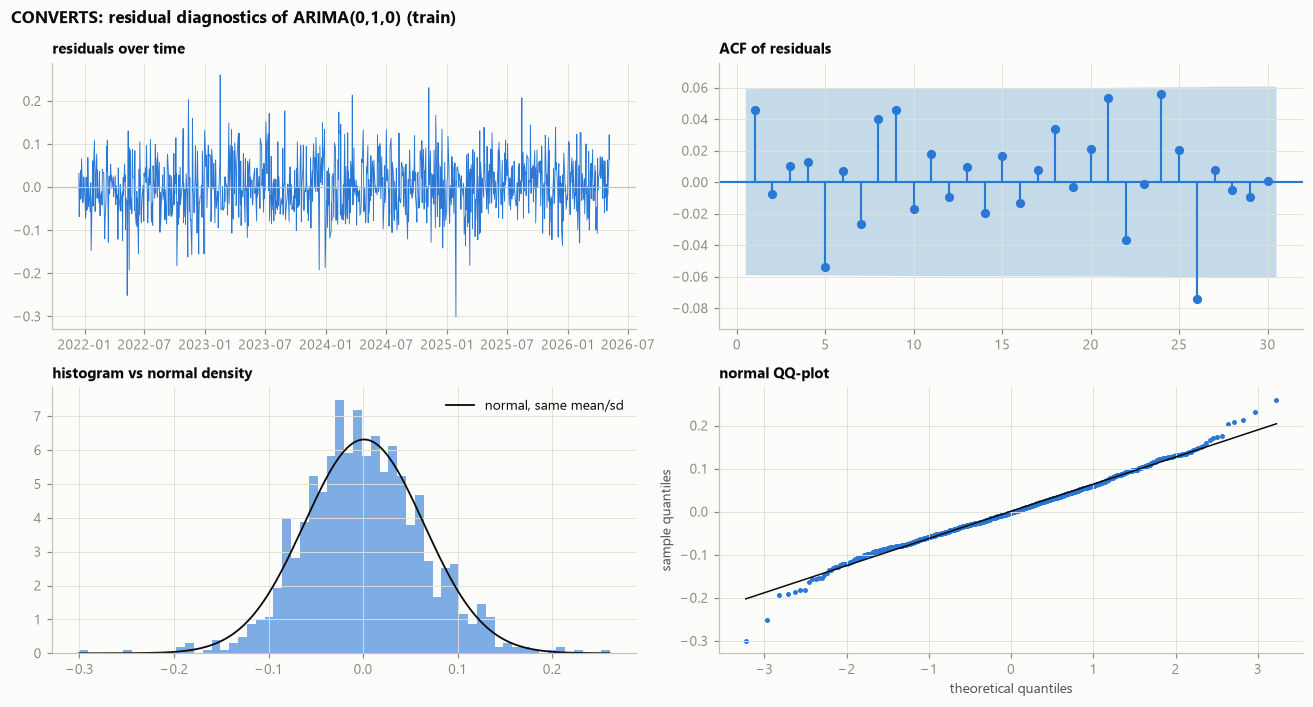

figures\fig_03_03_residuals_pure.png


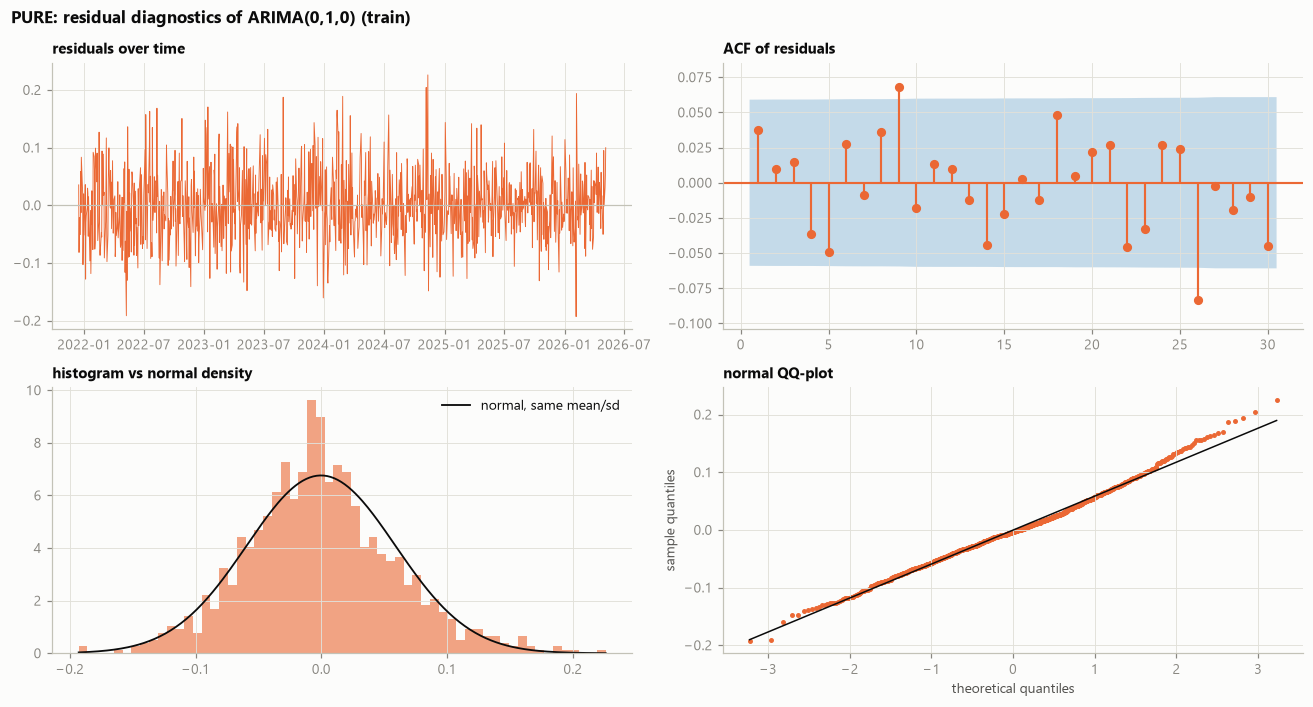

In [10]:
# Residual plots for CONVERTS: time, ACF, histogram vs normal, QQ-plot (brief §3.1).
def resid_panel(e: pd.Series, s: str, name: str, fname: str):
    fig, ax = plt.subplots(2, 2, figsize=(12, 6.5))
    ax[0, 0].plot(e.index, e, color=plotting.CORE[s], lw=0.6); ax[0, 0].axhline(0, color=plotting.AXIS, lw=0.8)
    ax[0, 0].set_title("residuals over time")
    plot_acf(e, lags=30, zero=False, ax=ax[0, 1], auto_ylims=True, color=plotting.CORE[s], vlines_kwargs={"colors": plotting.CORE[s]},
             title="ACF of residuals")
    ax[1, 0].hist(e, bins=60, density=True, color=plotting.CORE[s], alpha=0.6)
    xs = np.linspace(e.min(), e.max(), 300)
    ax[1, 0].plot(xs, stats.norm.pdf(xs, e.mean(), e.std()), color=plotting.INK, lw=1.2, label="normal, same mean/sd")
    ax[1, 0].legend(); ax[1, 0].set_title("histogram vs normal density")
    (osm, osr), (slope, icpt, _) = stats.probplot(e, dist="norm")
    ax[1, 1].scatter(osm, osr, s=5, color=plotting.CORE[s]); ax[1, 1].plot(osm, slope * osm + icpt, color=plotting.INK, lw=1)
    ax[1, 1].set_title("normal QQ-plot"); ax[1, 1].set_xlabel("theoretical quantiles"); ax[1, 1].set_ylabel("sample quantiles")
    fig.suptitle(f"{s}: residual diagnostics of {name} (train)", x=0.01, ha="left", fontweight="bold")
    fig.tight_layout(); print(plotting.save(fig, fname)); plt.show()

for s, fname in [("CONVERTS", "fig_03_02_residuals_converts"), ("PURE", "fig_03_03_residuals_pure")]:
    e = pd.Series(fits[(s, "ARIMA(0,1,0)")].resid[1:], index=y_tr[s].index[1:])
    resid_panel(e, s, "ARIMA(0,1,0)", fname)

**Test conclusions.**

**CONVERTS, ARIMA(0,1,0)**
* **Independence (Ljung-Box)**: H0 not rejected (p = 0.32 / 0.35 / 0.81 at lags 5 / 10 / 20). The residuals are white noise in the linear sense: the model has captured all linear dependence (there was none). The residual ACF stays inside the band.
* **Normality**: rejected by Jarque-Bera (JB = 43.8, p ≈ 3·10⁻¹⁰) and by Shapiro-Wilk (W = 0.992, p ≈ 2·10⁻⁵). The QQ-plot shows that the departure comes from **the tails**, in particular a few very large falls (−0.30 on 2025-01-27); the centre of the distribution is well normal. Consequence: Gaussian forecast intervals are slightly too narrow for extreme events.
* **Conditional heteroscedasticity (ARCH-LM)**: H0 **not rejected** (LM = 3.59, p = 0.61 at lag 5; p = 0.92 at lag 10). Ljung-Box on e² (p = 0.92) and on |e| (p = 0.22) point the same way. **No** ARCH effect is detected for CONVERTS in the training sample.

**PURE, ARIMA(0,1,0)**
* **Ljung-Box**: H0 not rejected (p = 0.30 / 0.18 / 0.43).
* **Normality**: rejected (JB = 29.0, p ≈ 5·10⁻⁷).
* **ARCH-LM**: **rejected** (LM = 16.4, p = 0.0057 at lag 5; p = 0.0047 at lag 10), confirmed by Ljung-Box on e² (p = 0.0011) and on |e| (p = 0.0010). The variance of PURE depends on its past.

**Consequence for Phase 5 (GARCH).**
* For PURE, ARCH-LM clearly motivates a GARCH.
* For CONVERTS, it does **not** on the training sample. This is an honest and surprising finding, since 20-day realised volatility visibly varies (fig. 02_04). Phase 5 must discuss it: a GARCH on CONVERTS may find weak or poorly identified persistence, and the test can be repeated on the full sample.

In [11]:
# ARCH-LM on two halves of the CONVERTS train sample: is the 'no ARCH' verdict stable, or diluted by mixing regimes?
e_c = pd.Series(fits[("CONVERTS", "ARIMA(0,1,0)")].resid[1:], index=y_tr["CONVERTS"].index[1:])
piv = pd.Timestamp(cfg["pivot_date"])
arch_sub = []
for lab, part in [("full train", e_c), ("pre-pivot", e_c[e_c.index < piv]), ("post-pivot (train)", e_c[e_c.index >= piv])]:
    for m in (5, 10):
        lm, p = arima.arch_lm(part, m)
        arch_sub.append({"period": lab, "n": len(part), "lag": m, "LM": lm, "p_value": p,
                         "conclusion (5%)": "reject H0" if p < 0.05 else "H0 not rejected"})
arch_sub = pd.DataFrame(arch_sub)
arch_sub.to_csv(RES / "03_archlm_converts_subperiods.csv", index=False)
arch_sub

,period,n,lag,LM,p_value,conclusion (5%)
0,full train,1101,5,3.5861,0.6104,H0 not rejected
1,full train,1101,10,4.5027,0.9218,H0 not rejected
2,pre-pivot,777,5,6.1146,0.2952,H0 not rejected
3,pre-pivot,777,10,9.9676,0.4433,H0 not rejected
4,post-pivot (train),324,5,2.6070,0.7603,H0 not rejected
5,post-pivot (train),324,10,11.4457,0.3239,H0 not rejected


**Is the "no ARCH" verdict for CONVERTS an artefact of mixing regimes?** No. ARCH-LM rejects H0 neither on the pre-pivot period (p = 0.30 at lag 5, 0.44 at lag 10), nor on the post-pivot part of the training sample (p = 0.76 and 0.32). The absence of a detectable ARCH effect is therefore stable over time. One possible explanation: the index averages three stocks whose own shocks arrive on different dates, and large isolated jumps dominate the variance without forming regular clusters. This is only a hypothesis, to be examined in Phase 5.

In [12]:
# Robustness promised in phase 2: impulse dummies on the CONVERTS outlier days of the train set. Do the order or normality change?
out = pd.read_csv(RES / "02_outliers.csv", parse_dates=["date"])
ret_tr = y_tr["CONVERTS"].diff().dropna()
dates = [d for d in out.loc[out["series"] == "CONVERTS", "date"] if d in ret_tr.index]
X = pd.DataFrame({f"d_{d.date()}": (ret_tr.index == d).astype(float) for d in dates}, index=ret_tr.index)
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    m_x = pm.auto_arima(ret_tr.to_numpy(), X=X.to_numpy(), d=0, seasonal=False, stepwise=True, suppress_warnings=True, error_action="ignore")
e_x = m_x.resid()
print(f"{len(dates)} dummies | order chosen on returns with dummies: {m_x.order} (intercept {m_x.with_intercept})")
print(f"Jarque-Bera without dummies: {stats.jarque_bera(e_c).statistic:.1f} | with dummies: {stats.jarque_bera(e_x).statistic:.1f} (p = {stats.jarque_bera(e_x).pvalue:.3g})")

11 dummies | order chosen on returns with dummies: (0, 0, 0) (intercept False)
Jarque-Bera without dummies: 43.8 | with dummies: 0.8 (p = 0.677)


**Robustness (shock dummies).** The 11 CONVERTS outlier days found in Phase 2 that fall in the training sample are added as dummies (one impulse per day) in a model on returns:
* `auto_arima` still chooses **(0,0,0)** on returns, i.e. (0,1,0) on the log price: **the order does not change**;
* Jarque-Bera goes from 43.8 to 0.8 (p = 0.68): **the non-normality comes entirely from these 11 days**.

The main model stays without dummies, as decided in Phase 2. These days are real events, and removing them would give too optimistic a picture of risk. This test only shows that the choice of order is not driven by the extreme values.

## 5. Forecasts h = 5 and h = 10 on the test sample

**Scheme: rolling origins, fixed parameters.** Parameters are estimated once on the training sample. Then, for each test day taken as origin (the first one is the last training day), we forecast the next 1 to 10 days, conditioning on all observations known at that date. There is no re-estimation: no test information enters the coefficients.
Why several origins rather than one: a single origin would give only **one** error at h = 5 and **one** at h = 10. With rolling origins we get ≈ 118 and 113 errors, which makes RMSE, MAE and the Diebold-Mariano test of Phase 7 possible.

**Models saved** in `results/forecasts_arima.csv` (common format: `date, model, series, origin, horizon, y_true, y_pred, lower, upper`, values in **index points**, 95% intervals):
* `rw` — naive random walk = **ARIMA(0,1,0) without drift, the chosen model**: forecast = last observed value, interval widening in √h;
* `arima_011` — ARIMA(0,1,1), the best model by AIC, kept as a competitor.

The level forecast is exp(log forecast), i.e. the **median** of the future level. The interval bounds are exp(log bounds), an exact interval for the level.

In [13]:
# Rolling origins = last train day + every test day except the last; horizons 1..10 from each.
H = 10
origins = panel.index[len(train) - 1: len(panel) - 1]
names = {"ARIMA(0,1,0)": "rw", "ARIMA(0,1,1)": "arima_011"}
fc = pd.concat([arima.rolling_forecasts(fits[(s, m)], logy[s], origins, H, names[m], s) for s in SERIES for m in MODELS],
               ignore_index=True)
fc.to_csv(RES / "forecasts_arima.csv", index=False, date_format="%Y-%m-%d")
print(f"{len(fc)} rows | origins {origins[0].date()} -> {origins[-1].date()} ({len(origins)})")
fc.head(3)

4740 rows | origins 2026-05-06 -> 2026-10-29 (123)


,date,model,series,origin,horizon,y_true,y_pred,lower,upper
0,2026-05-07,rw,CONVERTS,2026-05-06,1,281.9304,301.0475,265.9968,340.7169
1,2026-05-08,rw,CONVERTS,2026-05-06,2,285.7723,301.0475,252.7021,358.6421
2,2026-05-11,rw,CONVERTS,2026-05-06,3,274.7344,301.0475,242.9531,373.0334


In [14]:
# Preview of accuracy at h = 5 and 10 (the full comparison and the significance tests are Phase 7).
sc = arima.quick_scores(fc)
sc.to_csv(RES / "03_forecast_scores_preview.csv", index=False)
sc

,model,series,horizon,n_origins,RMSE,MAE,MAPE_%,coverage_95%
0,rw,CONVERTS,5,119,28.7678,23.4698,10.4713,96.6387
1,rw,CONVERTS,10,114,36.0976,28.2671,13.6126,98.2456
2,arima_011,CONVERTS,5,119,28.8478,23.5475,10.4987,98.3193
3,arima_011,CONVERTS,10,114,36.1490,28.3283,13.6223,99.1228
4,rw,PURE,5,119,7.2386,6.1067,9.4569,100.0000
5,rw,PURE,10,114,10.0125,8.2664,13.5859,98.2456
6,arima_011,PURE,5,119,7.2437,6.1045,9.4508,100.0000
7,arima_011,PURE,10,114,10.0125,8.2686,13.5828,99.1228


figures\fig_03_04_forecast_first_origin.png


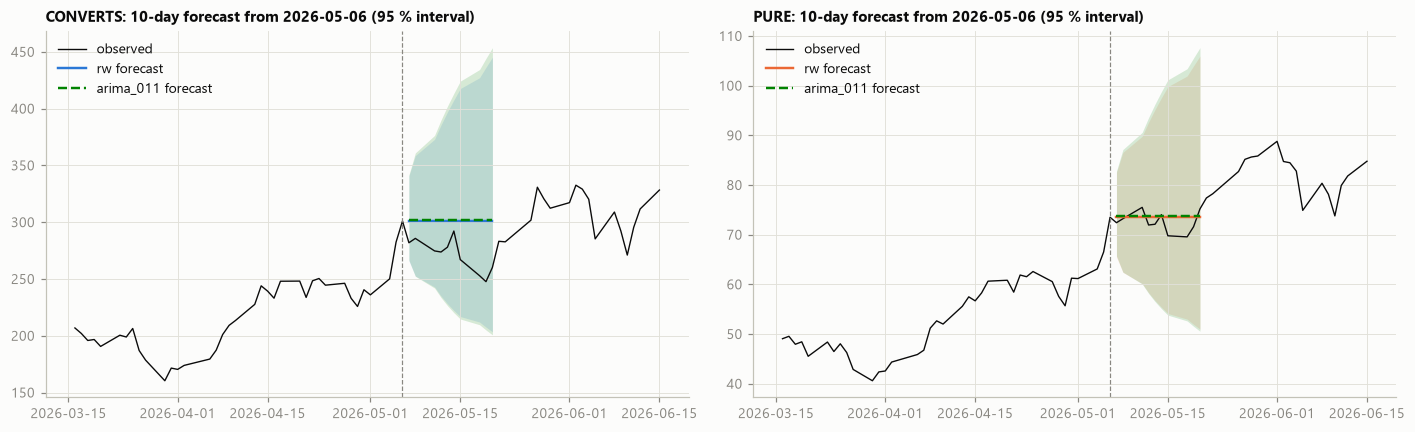

In [15]:
# Fan chart from the first origin (last train day): what a forecaster would have seen on 2026-05-06.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, s in zip(axes, SERIES):
    hist = np.exp(logy[s]).loc["2026-03-15":"2026-06-15"]
    ax.plot(hist.index, hist, color=plotting.INK, lw=0.9, label="observed")
    for m, col, ls in [("rw", plotting.CORE[s], "-"), ("arima_011", plotting.SERIES[5], "--")]:
        f = fc[(fc["series"] == s) & (fc["model"] == m) & (fc["origin"] == origins[0])]
        ax.plot(f["date"], f["y_pred"], color=col, lw=1.6, ls=ls, label=f"{m} forecast")
        ax.fill_between(f["date"], f["lower"], f["upper"], color=col, alpha=0.15, lw=0)
    ax.axvline(origins[0], color=plotting.MUTED, ls="--", lw=0.8)
    ax.set_title(f"{s}: 10-day forecast from {origins[0].date()} (95 % interval)"); ax.legend(loc="upper left")
fig.tight_layout(); print(plotting.save(fig, "fig_03_04_forecast_first_origin")); plt.show()

figures\fig_03_05_rolling_forecasts_converts.png


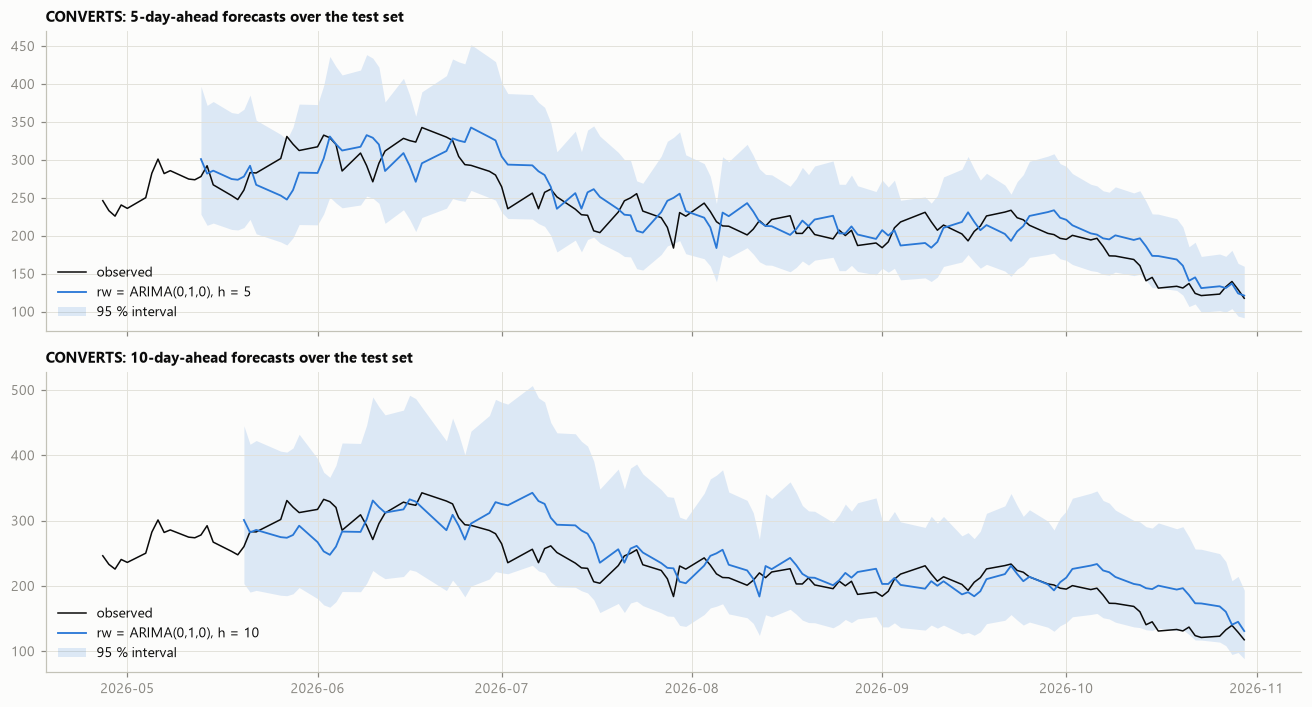

In [16]:
# h = 5 and h = 10 forecasts from every origin over the whole test set, CONVERTS, chosen model (rw) with its 95 % band.
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
obs = np.exp(logy["CONVERTS"]).loc[test.index[0] - pd.Timedelta(days=10):]
for ax, h in zip(axes, (5, 10)):
    f = fc[(fc["series"] == "CONVERTS") & (fc["model"] == "rw") & (fc["horizon"] == h)]
    ax.plot(obs.index, obs, color=plotting.INK, lw=1, label="observed")
    ax.plot(f["date"], f["y_pred"], color=plotting.CORE["CONVERTS"], lw=1.2, label=f"rw = ARIMA(0,1,0), h = {h}")
    ax.fill_between(f["date"], f["lower"], f["upper"], color=plotting.CORE["CONVERTS"], alpha=0.15, lw=0, label="95 % interval")
    ax.set_title(f"CONVERTS: {h}-day-ahead forecasts over the test set"); ax.legend(loc="lower left")
fig.tight_layout(); print(plotting.save(fig, "fig_03_05_rolling_forecasts_converts")); plt.show()

**Reading the forecasts.**

**Accuracy overview (over 119 origins at h = 5 and 114 at h = 10; RMSE and MAE in index points)**

| Series | Model | RMSE h=5 | RMSE h=10 | MAE h=5 | MAE h=10 | MAPE h=5 | MAPE h=10 | 95% coverage (h=5 / h=10) |
|---|---|---|---|---|---|---|---|---|
| CONVERTS | rw | 28.77 | 36.10 | 23.47 | 28.27 | 10.5% | 13.6% | 96.6% / 98.2% |
| CONVERTS | arima_011 | 28.85 | 36.15 | 23.55 | 28.33 | 10.5% | 13.6% | — |
| PURE | rw | 7.24 | 10.01 | 6.11 | 8.27 | 9.5% | 13.6% | — |
| PURE | arima_011 | 7.24 | 10.01 | 6.10 | 8.27 | 9.5% | 13.6% | — |

* **The error grows with the horizon**, as expected for a random walk: uncertainty accumulates in √h.
* **ARIMA(0,1,1) does not beat the random walk.** For CONVERTS it is even very slightly worse, and for PURE the differences are negligible: the MA parameter adds nothing out of sample. Whether these differences are significant is tested with Diebold-Mariano in Phase 7.
* **The 95% intervals contain the realised value in 96.6% (h = 5) and 98.2% (h = 10) of cases** for CONVERTS: they are rather conservative on this test. These rates are computed on overlapping origins, so they are not independent: it is an indication, not a test.
* **The forecast does not "see" the fall**: the test period was marked by a sharp fall of CONVERTS at the end (fig. 03_05). A random-walk forecast simply follows the level with a lag. This is exactly the property of a series whose returns are unpredictable, and it is the benchmark the models of Phases 4 and 6 must beat.

## 6. Python / R comparison

The detailed comparison (orders chosen by `auto.arima`, coefficients, log-likelihood, first forecast) is done in `notebooks/r/03_arima.Rmd`. That notebook reads `results/03_arima_python_coefs.csv` and `results/forecasts_arima.csv`.

Summary (numbers produced by the Rmd, `results/03_python_vs_r.csv`):
* **Same model**: `auto.arima` with d = 1 chooses **(0,1,0) without drift** for CONVERTS and PURE.
* **Same coefficients**: relative difference ≤ 1.5% on the MA coefficient of ARIMA(0,1,1) and ≤ 0.11% on σ²; log-likelihood difference < 0.0002.
* **Same tests**: the p-values of the residual diagnostics are identical to 3 decimals, and ARCH-LM is rejected for PURE, not for CONVERTS, in both languages.
* **Same forecasts**: from the first origin, the maximum relative difference is 5.5·10⁻⁵ on the point forecast and 2.4·10⁻⁴ on the 95% bounds.
* **Same trap with free d**: R chooses (5,2,0) and Python (5,2,1). Both over-difference, for the same reason (the default KPSS test).

## Phase 3 summary

1. **Chosen model: ARIMA(0,1,0) without drift** (a random walk) for CONVERTS and PURE. The manual choice, BIC and `auto_arima` / `auto.arima` (d = 1) agree. AIC very slightly prefers (0,1,1) (ΔAIC = 0.37), but its MA coefficient (0.047) is not significant.
2. **No SARIMA**: D = 0, seasonal terms not significant (p ≥ 0.07), worse BIC.
3. **Residuals**: no autocorrelation (Ljung-Box p ≥ 0.18), non-normal because of 11 extreme days (JB goes from 43.8 to 0.8 with dummies). **ARCH-LM rejects for PURE (p = 0.006) but not for CONVERTS (p = 0.61)**, neither before nor after the pivot.
4. **Forecasts** (rolling origins, `results/forecasts_arima.csv`): CONVERTS RMSE = 28.8 at h = 5 and 36.1 at h = 10 (MAPE 10.5% and 13.6%). ARIMA(0,1,1) does no better than the random walk.
5. **R and Python** give the same model, the same coefficients (difference ≤ 1.5%) and the same forecasts (difference ≤ 2.4·10⁻⁴).